In [30]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from collections import Counter
from google.colab import drive, files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [31]:
drive.mount("/content/drive")

DATASET_PATH = "/content/drive/MyDrive/Vehicles"

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_PATH}")

print("Dataset folders:", os.listdir(DATASET_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folders: ['.DS_Store', 'Trains', 'Motorcycles', 'Bikes', 'Planes', 'Ships', 'Cars', 'Auto Rickshaws']


# **Load and preprocess images**

In [32]:
IMG_SIZE = 64
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

images = []
labels = []

for folder in sorted(os.listdir(DATASET_PATH)):
    folder_path = os.path.join(DATASET_PATH, folder)

    if not os.path.isdir(folder_path):
        continue

    count_before = len(images)

    for filename in sorted(os.listdir(folder_path)):
        if not filename.lower().endswith(VALID_EXTENSIONS):
            continue

        image_path = os.path.join(folder_path, filename)

        try:
            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))

                images.append(np.asarray(img, dtype=np.uint8))
                labels.append(folder)

        except Exception as error:
            print("Skipped:", image_path, error)

    print(f"{folder}: {len(images) - count_before} images loaded")

if len(images) == 0:
    raise ValueError("No images found. Check your dataset path.")

X = np.asarray(images, dtype=np.float32)
y = np.asarray(labels)

print("\nTotal images:", len(X))
print("Image shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Auto Rickshaws: 800 images loaded
Bikes: 800 images loaded
Cars: 790 images loaded
Motorcycles: 816 images loaded
Planes: 800 images loaded
Ships: 800 images loaded
Trains: 800 images loaded

Total images: 5606
Image shape: (5606, 64, 64, 3)
Labels shape: (5606,)
Classes: ['Auto Rickshaws' 'Bikes' 'Cars' 'Motorcycles' 'Planes' 'Ships' 'Trains']


# **Normalize images and encode labels**

In [33]:
# Normalize pixel values from 0-255 to 0-1
X = X / 255.0

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

class_names = encoder.classes_
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Pixel range:", X.min(), "to", X.max())
print("Class counts:", Counter(y))

Classes: ['Auto Rickshaws' 'Bikes' 'Cars' 'Motorcycles' 'Planes' 'Ships' 'Trains']
Number of classes: 7
Pixel range: 0.0 to 1.0
Class counts: Counter({np.str_('Motorcycles'): 816, np.str_('Auto Rickshaws'): 800, np.str_('Bikes'): 800, np.str_('Planes'): 800, np.str_('Ships'): 800, np.str_('Trains'): 800, np.str_('Cars'): 790})


# **Split training, validation and testing data**

In [34]:
# First separate the final test set
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded)

In [36]:
# Separate validation data from training data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (3587, 64, 64, 3) (3587,)
Validation: (897, 64, 64, 3) (897,)
Testing: (1122, 64, 64, 3) (1122,)


# **Build the improved ANN model**

In [37]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Flatten, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.regularizers import l2

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    Flatten(),

    Dense(
        512,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.4),

    Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,460,167 (24.64 MB)

 Trainable params: 6,458,631 (24.64 MB)

 Non-trainable params: 1,536 (6.00 KB)

# **Compile the model**

In [38]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


# **Train the model**

In [39]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        "/content/best_vehicle_ann.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2788 - loss: 3.4388
Epoch 1: val_loss improved from None to 3.40268, saving model to /content/best_vehicle_ann.keras

Epoch 1: finished saving model to /content/best_vehicle_ann.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.3368 - loss: 3.1870 - val_accuracy: 0.2988 - val_loss: 3.4027 - learning_rate: 0.0010
Epoch 2/30
106/113 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3974 - loss: 2.8067
Epoch 2: val_loss improved from 3.40268 to 2.59181, saving model to /content/best_vehicle_ann.keras

Epoch 2: finished saving model to /content/best_vehicle_ann.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4251 - loss: 2.6690 - val_accuracy: 0.4103 - val_loss: 2.5918 - learning_rate: 0.0010
Epoch 3/30
107/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4399 - loss: 2.5308
Epoch 3: val_loss did not improve from 2.59181
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4561 - loss: 2.4302 - va

# **Plot accuracy and loss**

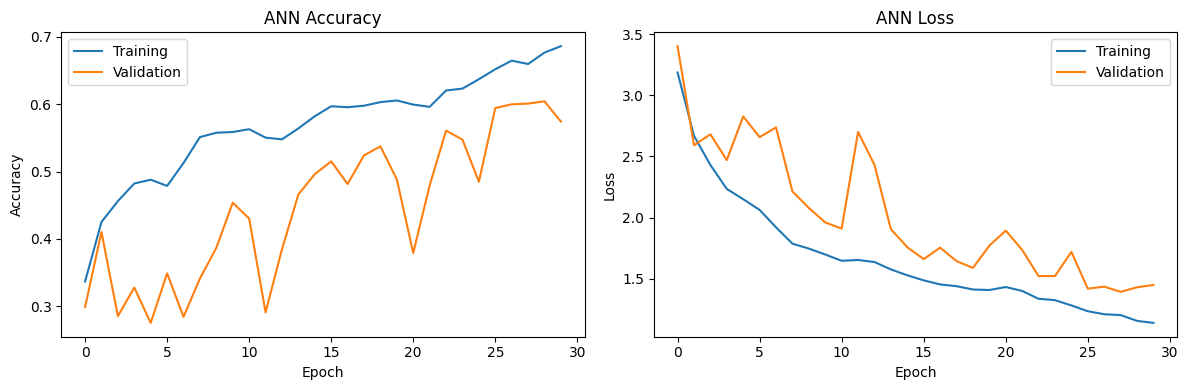

In [40]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# **Evaluate test accuracy**

In [41]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 1.3941
Test Accuracy: 61.32%


# **Classification report**

In [42]:
y_prob = model.predict(X_test, batch_size=32, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0))

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
                precision    recall  f1-score   support

Auto Rickshaws       0.73      0.46      0.56       160
         Bikes       0.77      0.75      0.76       160
          Cars       0.52      0.47      0.50       158
   Motorcycles       0.46      0.60      0.52       164
        Planes       0.67      0.75      0.71       160
         Ships       0.73      0.64      0.68       160
        Trains       0.53      0.62      0.57       160

      accuracy                           0.61      1122
     macro avg       0.63      0.61      0.61      1122
  weighted avg       0.63      0.61      0.61      1122



# **Confusion matrix**

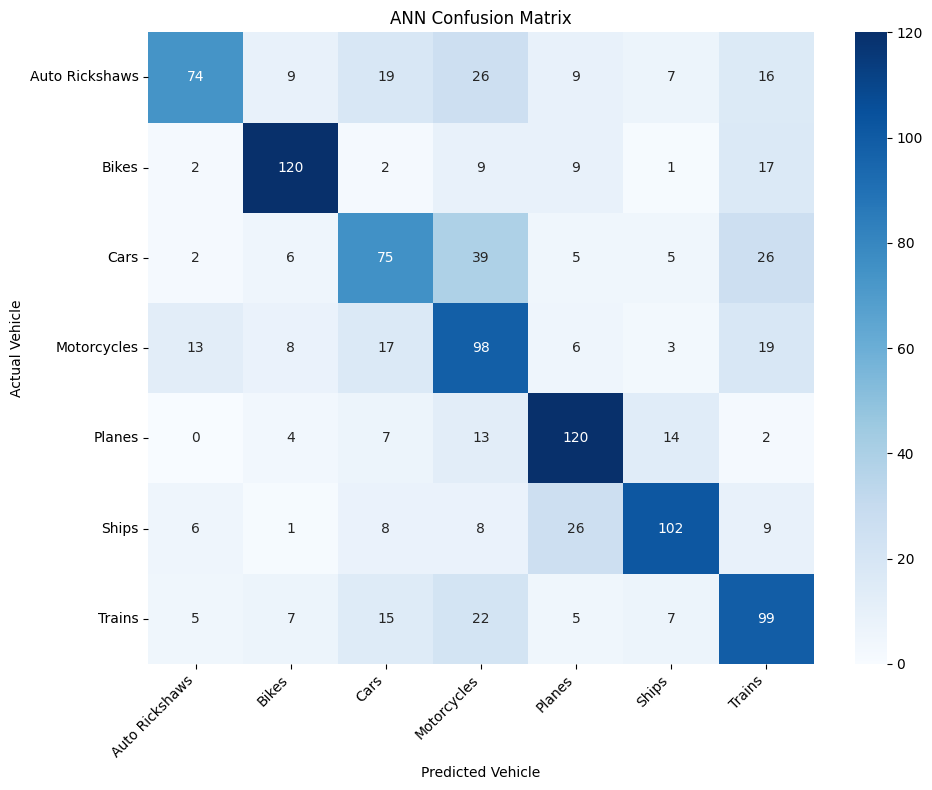

In [43]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Vehicle")
plt.ylabel("Actual Vehicle")
plt.title("ANN Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# **Predict a new vehicle image**

Saving Car (486).jpg to Car (486).jpg


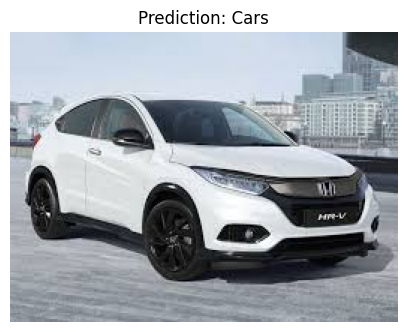

Predicted vehicle: Cars
Prediction probability: 92.49%


In [49]:
uploaded = files.upload()

for filename in uploaded.keys():
    with Image.open(filename) as img:
        original = img.convert("RGB")
        processed = original.resize((IMG_SIZE, IMG_SIZE))

        image_array = np.asarray(
            processed, dtype=np.float32
        ) / 255.0

    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(
        image_array, verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = probabilities[predicted_index] * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(original)
    plt.title(f"Prediction: {predicted_class}")
    plt.axis("off")
    plt.show()

    print("Predicted vehicle:", predicted_class)
    print(f"Prediction probability: {confidence:.2f}%")

# **Save model and label encoder**

In [48]:
MODEL_PATH = "/content/drive/MyDrive/vehicle_ann_model.keras"
ENCODER_PATH = "/content/drive/MyDrive/vehicle_label_encoder.pkl"

model.save(MODEL_PATH)

with open(ENCODER_PATH, "wb") as f:
    pickle.dump(encoder, f)

print("Model saved:", MODEL_PATH)
print("Label encoder saved:", ENCODER_PATH)

Model saved: /content/drive/MyDrive/vehicle_ann_model.keras
Label encoder saved: /content/drive/MyDrive/vehicle_label_encoder.pkl
